In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/digit-recognizer/sample_submission.csv
/kaggle/input/competitions/digit-recognizer/train.csv
/kaggle/input/competitions/digit-recognizer/test.csv


In [2]:
df = pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')

In [3]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
df.shape #784 features and 42000 images , label - tells which number is it

(42000, 785)

In [7]:
import matplotlib.pyplot as plt

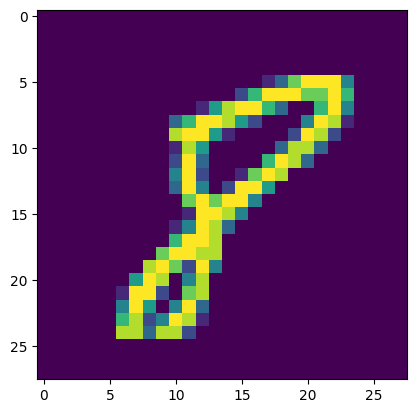

In [9]:
plt.imshow(df.iloc[18306,1:].values.reshape(28,28))

In [10]:
X = df.iloc[:,1:]
y = df.iloc[:,0]

In [12]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [13]:
X_train.shape

(33600, 784)

In [14]:
from sklearn.neighbors import KNeighborsClassifier

In [15]:
knn = KNeighborsClassifier()

In [16]:
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [18]:
import time
start = time.time()

y_pred = knn.predict(X_test)
print(time.time()-start) #faster bcz kaggle hardware is good but takes much longer as it calculates distance of each point from each other point

11.276479482650757


In [19]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9648809523809524

In [20]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [22]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [47]:
# PCA
from sklearn.decomposition import PCA
pca =  PCA(n_components=100) #taking only 100 columns

In [48]:
X_train_trf= pca.fit_transform(X_train)
X_test_trf= pca.transform(X_test)

In [49]:
X_train.shape

(33600, 100)

In [50]:
knn = KNeighborsClassifier()

In [51]:
knn.fit(X_train_trf,y_train)

KNeighborsClassifier()

In [52]:
y_pred = knn.predict(X_test_trf)

In [53]:
accuracy_score(y_test,y_pred)

0.9544047619047619

In [56]:
for i in range(1,785):
    pca =  PCA(n_components=i)
    X_train_trf= pca.fit_transform(X_train)
    X_test_trf= pca.transform(X_test)
    knn = KNeighborsClassifier()
    knn.fit(X_train_trf,y_train)
    y_pred = knn.predict(X_test_trf)
    print(accuracy_score(y_test,y_pred))

0.2580952380952381
0.3236904761904762
0.5104761904761905
0.6663095238095238
0.7378571428571429
0.8227380952380953
0.8436904761904762
0.8721428571428571
0.886547619047619
0.9055952380952381
0.9116666666666666
0.9184523809523809
0.9276190476190476
0.9351190476190476
0.9384523809523809
0.9379761904761905
0.9407142857142857
0.94
0.9425
0.9442857142857143
0.9438095238095238
0.9441666666666667
0.9442857142857143
0.9457142857142857
0.9484523809523809
0.9479761904761905
0.9478571428571428
0.9471428571428572
0.949047619047619
0.9491666666666667
0.9507142857142857
0.9513095238095238
0.95
0.9504761904761905
0.950952380952381
0.9519047619047619
0.9517857142857142
0.9527380952380953
0.9533333333333334
0.9528571428571428
0.9522619047619048
0.9522619047619048
0.9523809523809523
0.9533333333333334
0.9528571428571428
0.9530952380952381
0.9530952380952381
0.9533333333333334
0.9527380952380953
0.9533333333333334
0.9545238095238096
0.954047619047619
0.9541666666666667
0.9541666666666667
0.9546428571428571

KeyboardInterrupt: 

In [61]:
# transforming to a @d coordinate system
pca =  PCA(n_components=2)
X_train_trf= pca.fit_transform(X_train)
X_test_trf= pca.transform(X_test)

In [62]:
X_train_trf

array([[-2.71863253, -0.48982409],
       [-0.67698015, -6.75362491],
       [-3.03323281,  6.50981624],
       ...,
       [ 2.14883643,  0.78079444],
       [ 1.05957006,  0.94767312],
       [17.70258446,  1.96188185]])

In [67]:
import plotly.express as px

y_train_trf = y_train.astype(str)

fig = px.scatter(
    x=X_train_trf[:, 0],
    y=X_train_trf[:, 1],
    color=y_train_trf,
    color_discrete_sequence=px.colors.qualitative.G10
)

fig.show() #can't really differentiate well

In [64]:
pca =  PCA(n_components=3)
X_train_trf= pca.fit_transform(X_train)
X_test_trf= pca.transform(X_test)

In [65]:
X_train_trf

array([[-2.71863253, -0.48982409,  1.1354966 ],
       [-0.67698015, -6.75362491, -2.33590139],
       [-3.03323281,  6.50981624,  7.49182983],
       ...,
       [ 2.14883643,  0.78079444, -0.74738774],
       [ 1.05957006,  0.94767312,  3.94973114],
       [17.70258446,  1.96188185, -4.94352837]])

In [68]:
import plotly.express as px

y_train_trf = y_train.astype(str)

fig = px.scatter_3d(
    x=X_train_trf[:, 0],
    y=X_train_trf[:, 1],
    z=X_train_trf[:, 2],
    color=y_train_trf,
    color_discrete_sequence=px.colors.qualitative.G10
)

fig.show() #see how 3 and 8 are similar/intersection but 3 and 7 are not

In [71]:
pca.explained_variance_ 
#represents the eigen values or lambda 

array([40.67111198, 29.17023401, 26.74459621])

In [74]:
pca.components_.shape
#eigen vector

(3, 100)

In [80]:
pca.explained_variance_ratio_

array([0.08024204, 0.05755139, 0.05276573])

In [82]:
for i in range(1,785):
    pca =  PCA(n_components=None)
    X_train_trf= pca.fit_transform(X_train)
    X_test_trf= pca.transform(X_test)

In [83]:
pca.components_.shape


(100, 100)

In [85]:
pca.components_

array([[ 1.00000000e+00,  0.00000000e+00,  0.00000000e+00, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 0.00000000e+00,  1.00000000e+00, -1.99840144e-15, ...,
         4.21029096e-18,  4.27034673e-17,  2.92600447e-18],
       [-0.00000000e+00,  1.27675648e-15,  1.00000000e+00, ...,
         5.79585425e-18,  4.52666463e-17, -2.42128988e-17],
       ...,
       [-0.00000000e+00, -5.20417043e-18, -6.28837260e-18, ...,
         1.00000000e+00, -1.41692214e-14,  7.89749125e-15],
       [-0.00000000e+00,  6.93889390e-18, -0.00000000e+00, ...,
         1.40946282e-14,  1.00000000e+00,  1.33226763e-14],
       [-0.00000000e+00, -5.89805982e-17,  5.55111512e-17, ...,
        -7.90014755e-15, -1.37667655e-14,  1.00000000e+00]])

In [86]:
pca.explained_variance_ratio_

array([0.08024204, 0.05755139, 0.05276573, 0.04114279, 0.03580689,
       0.03127713, 0.02736694, 0.02462357, 0.02175757, 0.01991855,
       0.01900577, 0.01702233, 0.01590795, 0.01557667, 0.01468206,
       0.01414669, 0.0132832 , 0.0130756 , 0.01265645, 0.01234688,
       0.01165018, 0.01137448, 0.01089235, 0.01049617, 0.01022599,
       0.00973531, 0.00968032, 0.00930838, 0.00887481, 0.00874293,
       0.00853507, 0.00835528, 0.0080957 , 0.0080246 , 0.0079384 ,
       0.0075787 , 0.00753442, 0.00732589, 0.00712073, 0.00685212,
       0.00676412, 0.00668516, 0.00649411, 0.00637119, 0.00634787,
       0.00623078, 0.00616785, 0.00612428, 0.00603511, 0.0059924 ,
       0.00585059, 0.00580113, 0.00565898, 0.00557591, 0.00552502,
       0.00547318, 0.005366  , 0.00531501, 0.00522288, 0.00519016,
       0.00506059, 0.00500442, 0.00490849, 0.00482603, 0.00477585,
       0.00468728, 0.0046464 , 0.00460504, 0.00453392, 0.00444552,
       0.00442151, 0.00431904, 0.00429469, 0.00424195, 0.00421

In [89]:
np.cumsum(pca.explained_variance_ratio_)

array([0.08024204, 0.13779343, 0.19055916, 0.23170195, 0.26750884,
       0.29878597, 0.32615291, 0.35077648, 0.37253405, 0.3924526 ,
       0.41145837, 0.4284807 , 0.44438865, 0.45996531, 0.47464737,
       0.48879406, 0.50207727, 0.51515287, 0.52780932, 0.5401562 ,
       0.55180638, 0.56318086, 0.57407321, 0.58456937, 0.59479537,
       0.60453068, 0.614211  , 0.62351938, 0.63239419, 0.64113712,
       0.64967219, 0.65802747, 0.66612317, 0.67414777, 0.68208617,
       0.68966487, 0.69719929, 0.70452517, 0.7116459 , 0.71849802,
       0.72526214, 0.7319473 , 0.73844141, 0.7448126 , 0.75116047,
       0.75739125, 0.7635591 , 0.76968338, 0.77571849, 0.78171089,
       0.78756149, 0.79336262, 0.7990216 , 0.80459751, 0.81012253,
       0.81559571, 0.82096171, 0.82627672, 0.8314996 , 0.83668976,
       0.84175035, 0.84675476, 0.85166326, 0.85648929, 0.86126514,
       0.86595242, 0.87059881, 0.87520385, 0.87973776, 0.88418329,
       0.8886048 , 0.89292384, 0.89721853, 0.90146048, 0.90567

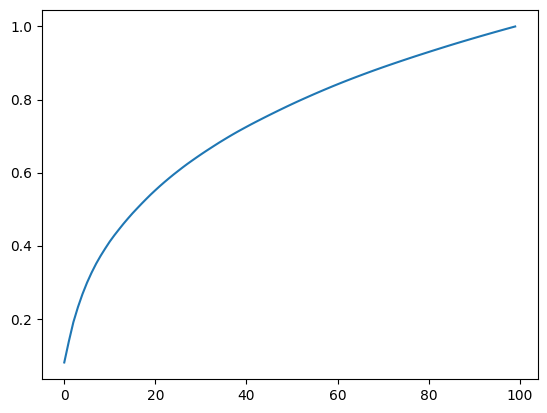

In [90]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))

In [91]:
#see the graph and see the number of components used to see atleast 90 percent of variance 